# Do Explicit Time-of-Day / Day-of-Week Buckets Improve Predictions?
> **Companion to notebooks 01-03.** The currently-served model already has
> *cyclical* time encodings (`hour_sin/cos`, `dow_sin/cos`) - smooth,
> continuous representations of time of day and day of week. This notebook
> tests a different hypothesis: does giving LightGBM an **explicit
> categorical** time-of-day bucket (night / morning / afternoon / evening,
> on Kyiv local time - not UTC, which the cyclical features use) and an
> explicit day-of-week category help it learn the dynamics better than the
> cyclical encoding alone?
>
> The intuition: a tree model *can* approximate a block boundary from
> `hour_sin`/`hour_cos` alone, but only by combining several splits across
> both dimensions at once. An explicit "is this a night alert" column makes
> that a single split.
>
> Same protocol as notebook 03: same model, same recency-weighting, same
> held-out recent test window, with and without the new features, starting
> from **today's actual production feature set** (region, elapsed time,
> cyclical time, and the neighbor-context features notebook 03 already
> justified adopting) - not an older baseline.
>
> *Disclaimer: statistical experiment for research and analysis. Decides
> nothing about the app by itself - see the verdict cell at the end.*


## 1. Setup & Imports


In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root / "src"))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from alertpred.config import OBLAST_NEIGHBORS, RECENCY_HALF_LIFE_DAYS, TASK_A_HORIZONS_MIN
from alertpred.data.build_dataset import build_master_alerts_dataset
from alertpred.data.cleaning import create_time_split
from alertpred.features.builder import (
    sample_as_of_alert_moments,
    sample_as_of_gap_moments,
    compute_recency_weight,
    compute_neighbor_active_features,
    compute_time_bucket_features,
)
from alertpred.models.quantile_lgbm import LightGBMQuantileModel, LightGBMProbabilityModel
from alertpred.evaluation.metrics import evaluate_quantile_predictions, evaluate_classification_probabilities

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

print(f"Project root: {project_root}")


Project root: /Users/allakovalcuk/Agentic_AI


## 2. Load the Master Dataset
Same pipeline as `train.py` / notebook 01.


In [2]:
df_alerts, df_gaps = build_master_alerts_dataset(use_api_backfill=True)
print(f"Alert episodes: {len(df_alerts):,}  |  Gap episodes: {len(df_gaps):,}")
print(f"Date range: {df_alerts['started_at'].min().strftime('%Y-%m-%d')} to {df_alerts['started_at'].max().strftime('%Y-%m-%d')}")


  [1/27] khmelnytskyi (uid=3): 108 completed episodes


  [2/27] vinnytsia (uid=4): 149 completed episodes


  [3/27] rivne (uid=5): 129 completed episodes


  [4/27] volyn (uid=8): 67 completed episodes


  [5/27] dnipropetrovsk (uid=9): 41 completed episodes (3 dropped, >72h merged chain)


...

  [24/27] donetsk (uid=28): 58 completed episodes
  [25/27] crimea (uid=29): 0 completed episodes


  [26/27] sevastopol (uid=30): 0 completed episodes


  [27/27] kyiv_city (uid=31): 218 completed episodes


Filling 4 days 21:41:48.292000 gap (2026-09-07 to 2026-09-12) with 578 volunteer-sourced episodes


Alert episodes: 90,077  |  Gap episodes: 90,046
Date range: 2022-03-15 to 2026-10-12


## 3. Chronological Split, Recency Weights, As-Of Samples
Identical to `train.py`'s production methodology.


In [3]:
TRAIN_RATIO = 0.80

alerts_train, alerts_test = create_time_split(df_alerts, timestamp_col='started_at', train_ratio=TRAIN_RATIO)
gaps_train, gaps_test = create_time_split(df_gaps, timestamp_col='gap_start', train_ratio=TRAIN_RATIO)

reference_ts = df_alerts['started_at'].max()
alerts_train['recency_weight'] = compute_recency_weight(alerts_train['started_at'], reference_ts, RECENCY_HALF_LIFE_DAYS)
gaps_train['recency_weight'] = compute_recency_weight(gaps_train['gap_start'], reference_ts, RECENCY_HALF_LIFE_DAYS)

train_a = sample_as_of_alert_moments(alerts_train)
test_a = sample_as_of_alert_moments(alerts_test)
train_b = sample_as_of_gap_moments(gaps_train)
test_b = sample_as_of_gap_moments(gaps_test)

train_a = train_a.merge(alerts_train[['region_id', 'started_at', 'recency_weight']].rename(columns={'started_at': 'start_ts'}), on=['region_id', 'start_ts'], how='left')
train_b = train_b.merge(gaps_train[['region_id', 'gap_start', 'recency_weight']].rename(columns={'gap_start': 'gap_start_ts'}), on=['region_id', 'gap_start_ts'], how='left')

print(f"Task A -> train: {len(train_a):,}, test: {len(test_a):,}")
print(f"Task B -> train: {len(train_b):,}, test: {len(test_b):,}")


Task A -> train: 494,635, test: 122,889
Task B -> train: 304,053, test: 53,258


## 4. Feature Setup: Today's Production Baseline + the New Hypothesis
`neighbors_active_*`/`national_active_count` (notebook 03) are already part
of the production feature set, so they're computed here as part of the
*baseline*, not the thing being tested. `time_of_day`/`day_of_week`
(Kyiv-local, see `features.builder.compute_time_bucket_features`) are the
new hypothesis.


In [4]:
train_a = compute_neighbor_active_features(train_a, df_alerts, OBLAST_NEIGHBORS)
test_a = compute_neighbor_active_features(test_a, df_alerts, OBLAST_NEIGHBORS)
train_b = compute_neighbor_active_features(train_b, df_alerts, OBLAST_NEIGHBORS)
test_b = compute_neighbor_active_features(test_b, df_alerts, OBLAST_NEIGHBORS)

for df in (train_a, test_a, train_b, test_b):
    bucket_feats = compute_time_bucket_features(df['as_of_ts'])
    df['time_of_day'] = bucket_feats['time_of_day']
    df['day_of_week'] = bucket_feats['day_of_week']

print("Time-of-day distribution (test set, Task A):")
display(test_a['time_of_day'].value_counts())
print()
print("Day-of-week distribution (test set, Task A):")
display(test_a['day_of_week'].value_counts())


Time-of-day distribution (test set, Task A):


time_of_day
evening      36271
afternoon    29076
night        28860
morning      28682
Name: count, dtype: int64


Day-of-week distribution (test set, Task A):


day_of_week
Friday       18620
Wednesday    17893
Thursday     17836
Sunday       17695
Monday       17293
Tuesday      16898
Saturday     16654
Name: count, dtype: int64

## 5. Task A: Production Baseline vs. + Time-of-Day/Day-of-Week
`time_of_day` and `day_of_week` are added to `categorical_cols` (alongside
`region_id`) so LightGBM treats them as categories with optimal splits,
the same way `region_id` already is - not as arbitrary ordinal numbers.


In [5]:
PRODUCTION_FEATURES_A = [
    'region_id', 'elapsed_min', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'month',
    'neighbors_active_count', 'neighbors_active_frac', 'national_active_count',
]
TIME_BUCKET_FEATURES = ['time_of_day', 'day_of_week']

results = []

for label, feature_cols, cat_cols in [
    ('Production (cyclical only)', PRODUCTION_FEATURES_A, ['region_id']),
    ('+ Time-of-Day/Day-of-Week', PRODUCTION_FEATURES_A + TIME_BUCKET_FEATURES, ['region_id'] + TIME_BUCKET_FEATURES),
]:
    quant = LightGBMQuantileModel(feature_cols=feature_cols, categorical_cols=cat_cols)
    quant.fit(train_a, target_col='target_remaining_min', weight_col='recency_weight')
    pred = quant.predict(test_a)
    m = evaluate_quantile_predictions(test_a['target_remaining_min'].values, pred['pred_p10'].values, pred['pred_p50'].values, pred['pred_p90'].values)
    results.append({'task': 'A', 'variant': label, **m})

    if label.startswith('+'):
        importances_a = pd.Series(quant.models[0.5].feature_importances_, index=feature_cols).sort_values(ascending=False)

df_res_a = pd.DataFrame(results).set_index(['task', 'variant'])
display(df_res_a.round(2))


mae_p50_min  median_ae_p50_min  \
task variant                                                      
A    Production (cyclical only)       119.33              48.45   
     + Time-of-Day/Day-of-Week        119.41              48.02   

                                 pinball_loss_p10  pinball_loss_p50  \
task variant                                                          
A    Production (cyclical only)             14.32             59.67   
     + Time-of-Day/Day-of-Week              14.33             59.71   

                                 pinball_loss_p90  mean_pinball_loss  \
task variant                                                           
A    Production (cyclical only)             50.38              41.46   
     + Time-of-Day/Day-of-Week              50.39              41.48   

                                 coverage_p10_p90  
task variant                                       
A    Production (cyclical only)              0.73  
     + Time-of-Day/Day-of-Week               0.73

LightGBM P50 feature importances, Task A, with time-of-day/day-of-week included:


hour_sin                  798
hour_cos                  733
month                     690
national_active_count     554
region_id                 510
elapsed_min               317
dow_sin                   274
neighbors_active_frac     204
neighbors_active_count    128
day_of_week               124
dow_cos                   122
time_of_day                29
is_weekend                 17
dtype: int32

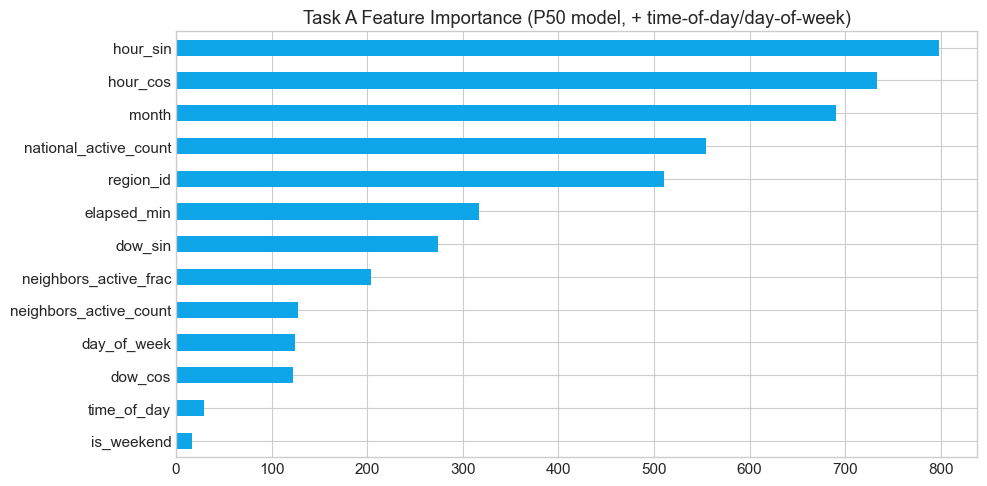

In [6]:
print("LightGBM P50 feature importances, Task A, with time-of-day/day-of-week included:")
display(importances_a)

plt.figure(figsize=(10, 5))
importances_a.sort_values().plot(kind='barh', color='#0ea5e9')
plt.title("Task A Feature Importance (P50 model, + time-of-day/day-of-week)")
plt.tight_layout()
plt.show()


## 6. Task B: Production Baseline vs. + Time-of-Day/Day-of-Week


In [7]:
PRODUCTION_FEATURES_B = [
    'region_id', 'elapsed_quiet_min', 'prev_alert_duration_min', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'month',
    'neighbors_active_count', 'neighbors_active_frac', 'national_active_count',
]

for label, feature_cols, cat_cols in [
    ('Production (cyclical only)', PRODUCTION_FEATURES_B, ['region_id']),
    ('+ Time-of-Day/Day-of-Week', PRODUCTION_FEATURES_B + TIME_BUCKET_FEATURES, ['region_id'] + TIME_BUCKET_FEATURES),
]:
    quant = LightGBMQuantileModel(feature_cols=feature_cols, categorical_cols=cat_cols)
    quant.fit(train_b, target_col='target_remaining_gap_min', weight_col='recency_weight')
    pred = quant.predict(test_b)
    m = evaluate_quantile_predictions(test_b['target_remaining_gap_min'].values, pred['pred_p10'].values, pred['pred_p50'].values, pred['pred_p90'].values)
    results.append({'task': 'B', 'variant': label, **m})

    if label.startswith('+'):
        importances_b = pd.Series(quant.models[0.5].feature_importances_, index=feature_cols).sort_values(ascending=False)

df_res_b = pd.DataFrame([r for r in results if r['task'] == 'B']).set_index(['task', 'variant'])
display(df_res_b.round(2))
print("\nFeature importances, Task B, with time-of-day/day-of-week included:")
display(importances_b)


mae_p50_min  median_ae_p50_min  \
task variant                                                      
B    Production (cyclical only)       603.07             193.52   
     + Time-of-Day/Day-of-Week        598.67             192.14   

                                 pinball_loss_p10  pinball_loss_p50  \
task variant                                                          
B    Production (cyclical only)             63.48            301.54   
     + Time-of-Day/Day-of-Week              63.95            299.33   

                                 pinball_loss_p90  mean_pinball_loss  \
task variant                                                           
B    Production (cyclical only)            271.26             212.09   
     + Time-of-Day/Day-of-Week             269.11             210.80   

                                 coverage_p10_p90  
task variant                                       
B    Production (cyclical only)              0.72  
     + Time-of-Day/Day-of-Week               0.72


Feature importances, Task B, with time-of-day/day-of-week included:


prev_alert_duration_min    1194
month                       573
hour_cos                    512
hour_sin                    480
region_id                   399
national_active_count       307
dow_sin                     276
elapsed_quiet_min           254
dow_cos                     162
neighbors_active_frac       136
day_of_week                  88
neighbors_active_count       74
time_of_day                  28
is_weekend                   17
dtype: int32

## 7. Probability Classifiers: Does Calibration Improve?
Unlike notebook 03 (which found no benefit from neighbor features here and
so left the classifiers alone), this hypothesis is checked against the
classifiers too since there's no prior result ruling it out.


In [8]:
prob_results = []
for label, feature_cols, cat_cols in [
    ('Production (cyclical only)', PRODUCTION_FEATURES_A, ['region_id']),
    ('+ Time-of-Day/Day-of-Week', PRODUCTION_FEATURES_A + TIME_BUCKET_FEATURES, ['region_id'] + TIME_BUCKET_FEATURES),
]:
    probs = LightGBMProbabilityModel(target_horizons=TASK_A_HORIZONS_MIN, horizon_prefix='ends_within_', horizon_suffix='m', feature_cols=feature_cols, categorical_cols=cat_cols)
    probs.fit(train_a, weight_col='recency_weight')
    pred_proba = probs.predict_proba(test_a)
    for h in TASK_A_HORIZONS_MIN:
        target_col = f'target_ends_within_{h}m'
        prob_col = f'prob_ends_within_{h}m'
        m = evaluate_classification_probabilities(test_a[target_col].values, pred_proba[prob_col].values)
        prob_results.append({'variant': label, 'horizon_min': h, **m})

df_prob = pd.DataFrame(prob_results).set_index(['horizon_min', 'variant'])
display(df_prob.round(4))


,,brier_score,accuracy,roc_auc,log_loss
horizon_min,variant,,,,
15,Production (cyclical only),0.1477,0.8088,0.6442,0.4678
30,Production (cyclical only),0.2166,0.6637,0.6499,0.6241
60,Production (cyclical only),0.2300,0.6228,0.6733,0.6568
15,+ Time-of-Day/Day-of-Week,0.1474,0.8095,0.6439,0.4674
30,+ Time-of-Day/Day-of-Week,0.2170,0.6628,0.6482,0.6250
60,+ Time-of-Day/Day-of-Week,0.2300,0.6254,0.6744,0.6570


## 8. Verdict
Same scoring as notebook 03: compares MAE and pinball loss (lower is
better) across every (task, variant) pair. A recommendation to weigh, not
a decision already made - this notebook changes nothing in `train.py` or
the app by itself.


In [9]:
summary = pd.DataFrame(results)
pivot = summary.pivot(index='task', columns='variant', values=['mae_p50_min', 'mean_pinball_loss', 'coverage_p10_p90'])
display(pivot.round(2))

for task in ['A', 'B']:
    base = summary[(summary['task'] == task) & (summary['variant'].str.startswith('Production'))].iloc[0]
    new = summary[(summary['task'] == task) & (summary['variant'].str.startswith('+'))].iloc[0]
    mae_delta_pct = 100 * (new['mae_p50_min'] - base['mae_p50_min']) / base['mae_p50_min']
    pinball_delta_pct = 100 * (new['mean_pinball_loss'] - base['mean_pinball_loss']) / base['mean_pinball_loss']
    print(f"Task {task}: + time-of-day/day-of-week {'improves' if mae_delta_pct < 0 else 'worsens'} MAE by {abs(mae_delta_pct):.1f}% "
          f"({'improves' if pinball_delta_pct < 0 else 'worsens'} pinball loss by {abs(pinball_delta_pct):.1f}%)")

print(f"\nTask A new-feature importance rank (of {len(PRODUCTION_FEATURES_A) + len(TIME_BUCKET_FEATURES)} features): "
      f"{[f for f in importances_a.index if f in TIME_BUCKET_FEATURES]}")
print("(top of the list = most used by the model; compare position against elapsed_min/region_id/hour_sin)")


mae_p50_min                             \
variant + Time-of-Day/Day-of-Week Production (cyclical only)   
task                                                           
A                          119.41                     119.33   
B                          598.67                     603.07   

                mean_pinball_loss                             \
variant + Time-of-Day/Day-of-Week Production (cyclical only)   
task                                                           
A                           41.48                      41.46   
B                          210.80                     212.09   

                 coverage_p10_p90                             
variant + Time-of-Day/Day-of-Week Production (cyclical only)  
task                                                          
A                            0.73                       0.73  
B                            0.72                       0.72

Task A: + time-of-day/day-of-week worsens MAE by 0.1% (worsens pinball loss by 0.0%)
Task B: + time-of-day/day-of-week improves MAE by 0.7% (improves pinball loss by 0.6%)

Task A new-feature importance rank (of 13 features): ['day_of_week', 'time_of_day']
(top of the list = most used by the model; compare position against elapsed_min/region_id/hour_sin)
